<a href="https://colab.research.google.com/github/freitas-econophys/Fisica_com_python1/blob/main/hopfield_model1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 3/3 [00:00<00:00, 11.17it/s]


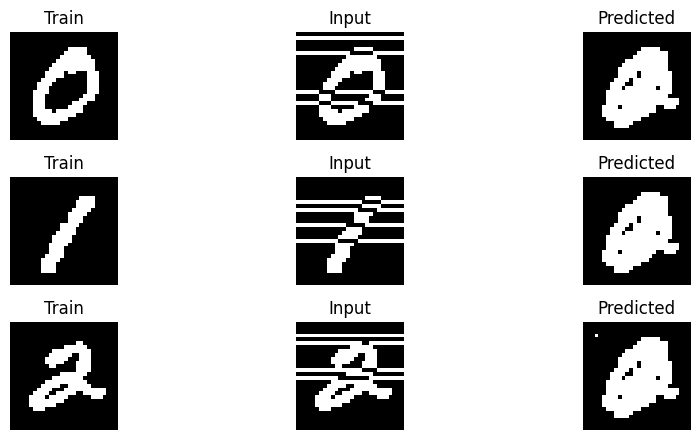

In [23]:
# Importando todas as bibliotecas necessárias ao programa.
!pip install scikit-image tqdm

import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_mean
from tqdm import tqdm
from tensorflow.keras.datasets import mnist

# Definições básicas da rede de Hopfield
# Realizei alguns ajustes com relação ao modelo para poder trabalhar com o padrão bipolar (spins \in {-1, +1}).
class HopfieldNetwork:
    def __init__(self):
        self.W = None
        self.num_neurons = 0
        self.rho = 0.0

    def train_weights(self, train_data):
        train_data = np.array(train_data) # Criando um array bidimensional padrão x neurônios
        self.num_neurons = train_data.shape[1] # Definindo a quantidade de neurônios na rede
        num_pattern = train_data.shape[0] # Definindo a quantidade de padrões

        a = np.mean(train_data) # Taxa média de atividade
        centered_data = train_data - a # Centralização dos dados em torno da média "a"

        W = np.dot(centered_data.T, centered_data) / self.num_neurons
        np.fill_diagonal(W, 0) # retirando as auto-interações
        self.W = W # salvando os pesos na instância

    def predict(self, data, num_iter=20, threshold=0, asyn=True):
        pred_all = []
        energies_all = []

        for s in tqdm(data):
            s = s.copy() # cópia de segurança
            e_list = [self.energy(s)]

            for _ in range(num_iter): #incluir as atualizações sincronizadas e assíncronas
                if asyn:
                    for _ in range(self.num_neurons):
                        i = np.random.randint(0, self.num_neurons)
                        h_i = np.dot(self.W[i], s) - threshold
                        val = np.sign(h_i)
                        s[i] = 1 if val >= 0 else -1
                else:
                    h = np.dot(self.W, s) - threshold
                    s = np.sign(h)
                    s[s == 0] = 1

                e_new = self.energy(s)
                e_list.append(e_new)

                if len(e_list) > 1 and e_new == e_list[-2]:
                    break

            pred_all.append(s.copy())
            energies_all.append(e_list)

        return pred_all, energies_all

    def energy(self, s):
        """Cálculo da energia no estado bipolar s."""
        return -0.5 * np.dot(s, np.dot(self.W, s))


# Definições das funções auxiliares

def preprocess(img):
    return 2 * (img > threshold_mean(img)).astype(int) - 1

def reshape_img(v):
    dim = int(np.sqrt(v.size))
    return v.reshape((dim, dim))

def plot_results(train, test, predicted):
    train = [reshape_img(d) for d in train]
    test = [reshape_img(d) for d in test]
    predicted = [reshape_img(d) for d in predicted]

    fig, axes = plt.subplots(len(train), 3, figsize=(10, 1.5 * len(train)))
    if len(train) == 1:
        axes = [axes]
    for i in range(len(train)):
        for j, data in enumerate([train[i], test[i], predicted[i]]):
            axes[i][j].imshow(data, cmap='gray')
            axes[i][j].axis('off')
            axes[i][j].set_title(["Train", "Input", "Predicted"][j])
    plt.tight_layout()
    plt.show()

def hamming_distance(a, b):
    return np.sum(a != b)


# Realizando o treinamento

(x_train, y_train), _ = mnist.load_data()

# escolhendo 3 imagens distintas do MNIST
train_imgs = [preprocess(x_train[y_train == i][0].astype(float)) for i in range(3)]

# Criando imagens de teste
test_imgs = []
for img in train_imgs:
    noisy_img = img.copy()

    idx_to_flip = np.random.choice(len(img), size=int(0.15 * len(img)), replace=False) #15% dos pixels invertidos
    noisy_img[idx_to_flip] *= -1
    test_imgs.append(noisy_img)

flattened_train_imgs = [img.flatten() for img in train_imgs]
flattened_test_imgs = [img.flatten() for img in test_imgs]

# Treinamento da rede
model = HopfieldNetwork()
model.train_weights(flattened_train_imgs)

# Trabahlando na previsão da rede
predicted, energies = model.predict(flattened_test_imgs, num_iter=20, asyn=True)

# Resultado final
plot_results(train_imgs, test_imgs, predicted)